In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load data
df = pd.read_csv('client_database.csv')

# 2. Basic cleaning & feature engineering
df['transaction_date'] = pd.to_datetime(df['transaction_date'])
df['year'] = df['transaction_date'].dt.year
df['month'] = df['transaction_date'].dt.month
df['day'] = df['transaction_date'].dt.day
df['weekday'] = df['transaction_date'].dt.day_name()

In [27]:
# 3. RFM Analysis
reference_date = df['transaction_date'].max()
rfm = df.groupby('client_id').agg({
    'transaction_date': lambda x: (reference_date - x.max()).days,
    'transaction_id': 'count',
    'amount': 'sum'
}).reset_index()
rfm.columns = ['client_id', 'Recency', 'Frequency', 'Monetary']
rfm['R_score'] = pd.qcut(rfm['Recency'], 4, labels=[4,3,2,1])
rfm['F_score'] = pd.qcut(rfm['Frequency'], 4, labels=[1,2,3,4])
rfm['M_score'] = pd.qcut(rfm['Monetary'], 4, labels=[1,2,3,4])
rfm['RFM_Segment'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)
rfm['RFM_Score'] = rfm[['R_score','F_score','M_score']].astype(int).sum(axis=1)

rfm

,client_id,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_Segment,RFM_Score
0,C001,5,13,5459.57,2,4,3,243,9
1,C002,2,8,4246.56,4,1,1,411,6
2,C003,0,8,5178.64,4,1,2,412,7
3,C004,1,12,5183.33,4,3,3,433,10
4,C005,37,10,5516.72,1,2,4,124,7
5,C006,56,6,3852.90,1,1,1,111,3
6,C007,2,10,4526.89,4,2,2,422,8
7,C008,9,13,6489.49,2,4,4,244,10
8,C009,3,7,3353.49,3,1,1,311,5
9,C010,15,13,6710.58,1,4,4,144,9


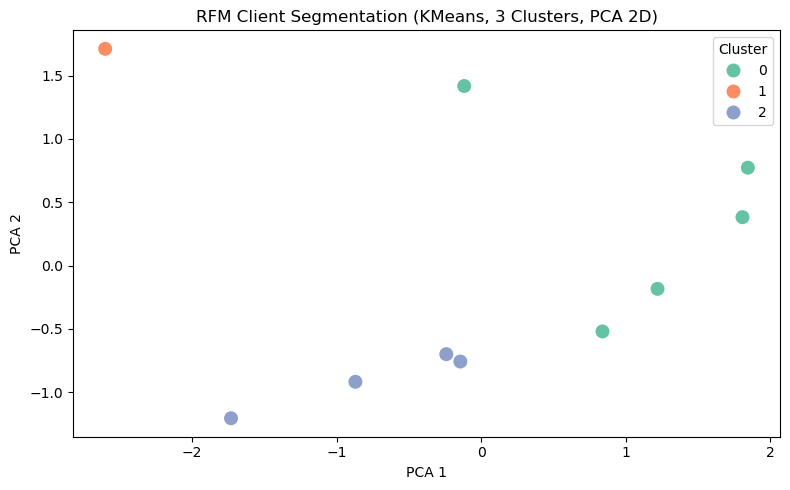

In [28]:
# 4. KMeans Clustering on RFM
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

X = rfm[['Recency', 'Frequency', 'Monetary']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
kmeans = KMeans(n_clusters=3, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(X_scaled)

# (Optional) PCA visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=rfm['Cluster'], palette="Set2", s=120)
plt.title("RFM Client Segmentation (KMeans, 3 Clusters, PCA 2D)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [29]:
# 5. Monthly Forecasting with Machine Learning

monthly_df = df.groupby(['year', 'month'])['amount'].sum().reset_index()
monthly_df['date'] = pd.to_datetime(monthly_df[['year', 'month']].assign(day=1))
monthly_df['prev_amount'] = monthly_df['amount'].shift(1)
monthly_df['prev2_amount'] = monthly_df['amount'].shift(2)
monthly_df_model = monthly_df.dropna()
X = monthly_df_model[['prev_amount', 'prev2_amount']]
y = monthly_df_model['amount']
X_train, X_test = X.iloc[:-1], X.iloc[-1:]
y_train, y_test = y.iloc[:-1], y.iloc[-1:]

from sklearn.ensemble import RandomForestRegressor
rf = RandomForestRegressor(random_state=42, n_estimators=100)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
y_train_pred = rf.predict(X_train)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
train_r2 = r2_score(y_train, y_train_pred)
print(f"Test MAE: {mae:.2f}, RMSE: {rmse:.2f}, R2 (Train): {train_r2:.2f}")

Test MAE: 4247.34, RMSE: 4247.34, R2 (Train): 0.71


/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_regression.py:1211: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


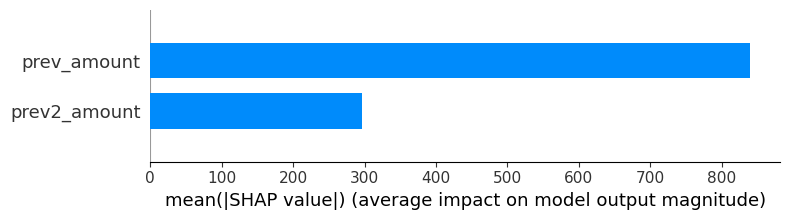

In [30]:
# 6. SHAP Analysis (Run this locally)
try:
    import shap
    explainer = shap.TreeExplainer(rf)
    shap_values = explainer.shap_values(X_train)
    shap.summary_plot(shap_values, X_train, plot_type="bar")
except Exception as e:
    print("SHAP plot requires local Python environment with SHAP installed. Error:", e)
